In [4]:
print("Jupyter is working!")


Jupyter is working!


Tracts across DART counties: 1123


<Axes: >

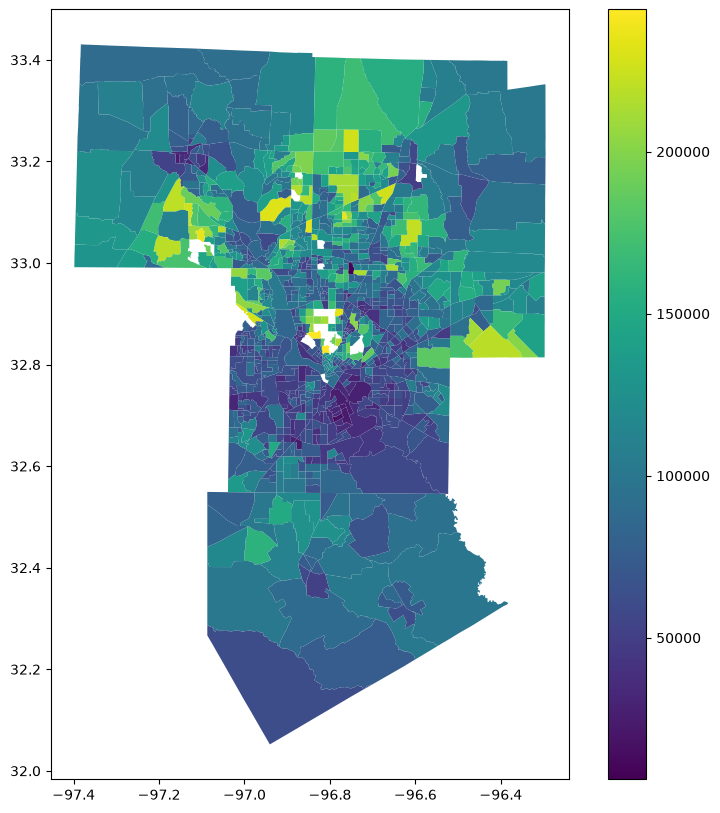

In [5]:
import geopandas as gpd
import pandas as pd

tracts = gpd.read_file("shapefiles/tl_2025_48_tract.shp")
tracts["GEOID"] = tracts["GEOID"].astype(str)

dart_counties = ["113", "085", "121", "397", "139"]  # Dallas, Collin, Denton, Rockwall, Ellis
dart = tracts[tracts["COUNTYFP"].isin(dart_counties)].copy()
print(f"Tracts across DART counties: {len(dart)}")

income = pd.read_csv("census/income_2023.csv", skiprows=[1])
income["GEOID"] = income["GEO_ID"].str.split("US").str[1]
income = income[["GEOID", "B19013_001E"]].rename(columns={"B19013_001E": "median_income"})
income["median_income"] = pd.to_numeric(income["median_income"], errors="coerce")

dart = dart.merge(income, on="GEOID")

dart.plot(column="median_income", legend=True, figsize=(10, 10))


In [6]:
dart[dart["median_income"].isna()]

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,median_income
117,48,113,019301,48113019301,1400000US48113019301,193.01,Census Tract 193.01,G5020,S,1199676,0,+32.8563450,-096.7818523,"POLYGON ((-96.78698 32.85704, -96.78695 32.858...",NaN
119,48,113,019501,48113019501,1400000US48113019501,195.01,Census Tract 195.01,G5020,S,2896843,0,+32.8580225,-096.7993959,"POLYGON ((-96.81314 32.85141, -96.81287 32.853...",NaN
222,48,113,020600,48113020600,1400000US48113020600,206,Census Tract 206,G5020,S,5323283,0,+32.8727219,-096.8216046,"POLYGON ((-96.8386 32.87044, -96.83858 32.8709...",NaN
245,48,085,031706,48085031706,1400000US48085031706,317.06,Census Tract 317.06,G5020,S,1814742,24760,+32.9930127,-096.8209776,"POLYGON ((-96.8294 32.99162, -96.82939 32.9921...",NaN
255,48,113,008000,48113008000,1400000US48113008000,80,Census Tract 80,G5020,S,5855428,2047039,+32.8363823,-096.7344154,"POLYGON ((-96.75298 32.83642, -96.75286 32.836...",NaN
272,48,113,980100,48113980100,1400000US48113980100,9801,Census Tract 9801,G5020,S,5549416,0,+32.8454803,-096.8492653,"POLYGON ((-96.86907 32.84576, -96.86893 32.846...",NaN
412,48,113,010002,48113010002,1400000US48113010002,100.02,Census Tract 100.02,G5020,S,1775475,0,+32.7727791,-096.8133108,"POLYGON ((-96.82242 32.77999, -96.82077 32.780...",NaN
552,48,113,019502,48113019502,1400000US48113019502,195.02,Census Tract 195.02,G5020,S,2074305,0,+32.8446067,-096.8063186,"POLYGON ((-96.81485 32.83683, -96.81477 32.837...",NaN
553,48,113,019600,48113019600,1400000US48113019600,196,Census Tract 196,G5020,S,1015403,0,+32.8314269,-096.7876412,"POLYGON ((-96.7955 32.82342, -96.79463 32.8243...",NaN
554,48,113,019700,48113019700,1400000US48113019700,197,Census Tract 197,G5020,S,2137907,0,+32.8328280,-096.7967924,"POLYGON ((-96.80436 32.83757, -96.80436 32.838...",NaN


In [7]:
lodes = pd.read_csv("lodes/tx_wac_S000_JT00_2023.csv.gz")
print(f"LODES shape: {lodes.shape}")
print(lodes[["w_geocode", "C000"]].head())
print(f"\nExample w_geocode: {lodes['w_geocode'].iloc[0]}")
print(f"Number of digits: {len(str(lodes['w_geocode'].iloc[0]))}")      

LODES shape: (168581, 53)
         w_geocode  C000
0  480019501001005    23
1  480019501001009   119
2  480019501001010    37
3  480019501001012    22
4  480019501001013     6

Example w_geocode: 480019501001005
Number of digits: 15


In [8]:
# extract the 11 digit tract GEOID from the 15 digit block code
lodes["GEOID"] = lodes["w_geocode"].astype(str).str.zfill(15).str[:11]

# group by tract and sum up all the jobs in each tract
jobs_by_tract = lodes.groupby("GEOID")["C000"].sum().reset_index()
jobs_by_tract = jobs_by_tract.rename(columns={"C000": "total_jobs"})

print(f"Number of tracts with jobs: {len(jobs_by_tract)}")
print(jobs_by_tract.head())

Number of tracts with jobs: 6880
         GEOID  total_jobs
0  48001950100         948
1  48001950401         157
2  48001950500         954
3  48001950600        1194
4  48001950700        1590


In [9]:
# joining jobs onto the dallas tracts which already have income
dallas = dallas.merge(jobs_by_tract, on="GEOID", how="left")

print(f"Dallas tracts: {len(dallas)}")
print(dallas[["GEOID", "median_income", "total_jobs"]].head())
print(f"\nTotal jobs across Dallas County: {dallas['total_jobs'].sum():,.0f}")

NameError: name 'dallas' is not defined

<Axes: >

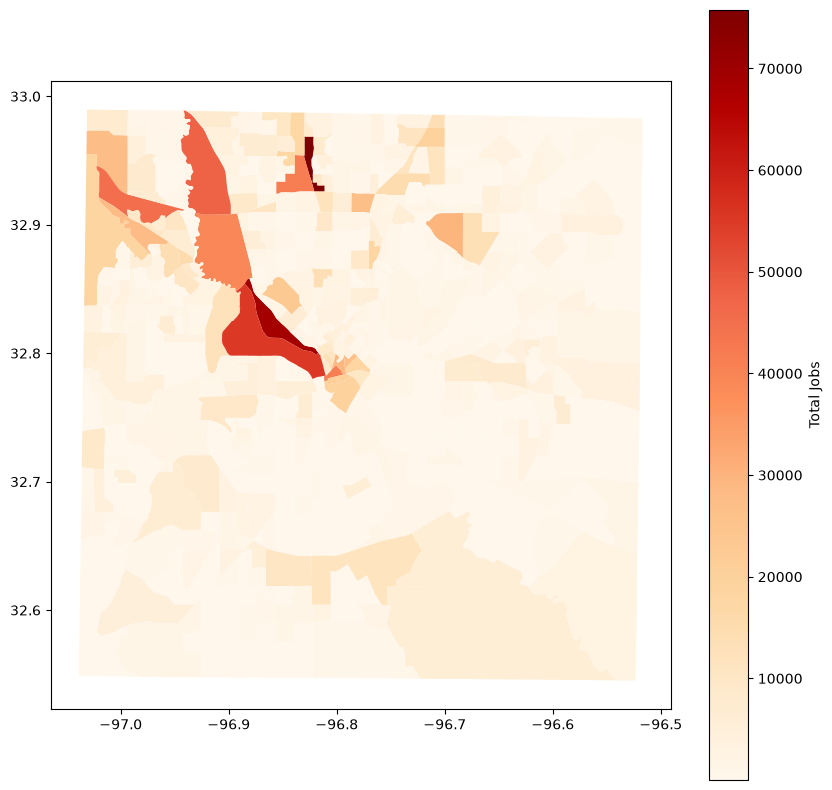

In [ ]:
dallas.plot(column="total_jobs", legend=True, figsize=(10, 10), 
            cmap="OrRd", legend_kwds={"label": "Total Jobs"})

In [ ]:
import r5py
print("r5py imported successfully!")
print(f"r5py version: {r5py.__version__}")

r5py imported successfully!
r5py version: 1.1.6


In [ ]:
import geopandas as gpd
import datetime
from r5py import TransportNetwork, TravelTimeMatrixComputer
from shapely.geometry import Point

# combines osm and GTFS
print("Building transport network")
network = TransportNetwork(
    "osm/texas-latest.osm.pbf",
    ["gtfs/google_transit.zip"]
)
print("Network built!")

ImportError: cannot import name 'TravelTimeMatrixComputer' from 'r5py' (/Users/sanjulajuttada/Downloads/transit_research/.venv/lib/python3.14/site-packages/r5py/__init__.py)

In [ ]:
import r5py
print([x for x in dir(r5py) if not x.startswith("_")])

['DetailedItineraries', 'ElevationCostFunction', 'Isochrones', 'RegionalTask', 'TransportMode', 'TransportNetwork', 'TravelTimeMatrix', 'r5', 'util']


In [ ]:
import geopandas as gpd
import datetime
from r5py import TransportNetwork, Isochrones
from shapely.geometry import Point

# combines osm and gtfs
print("Building transport network")
network = TransportNetwork(
    "osm/texas-260622.osm.pbf",
    ["gtfs/google_transit.zip"]
)
print("Network built!")

Building transport network


java.lang.IllegalArgumentException: java.lang.IllegalArgumentException: Geographic extent of street layer (1541721 km2) exceeds limit of 975000 km2.

In [ ]:
import geopandas as gpd
import datetime
from r5py import TransportNetwork, Isochrones
from shapely.geometry import Point

# transport network
print("Building transport network")
network = TransportNetwork(
    "osm/dfw.osm.pbf",
    ["gtfs/google_transit.zip"]
)
print("Network built!")

Building transport network


GtfsFileError: Could not load GTFS file google_transit.zip. 
RangeError: fare_attributes line 4: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 15: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 19: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 11: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 23: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 26: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 7: Number 2678400.0 outside of acceptable range [0.0,86400.0].

In [ ]:
import geopandas as gpd
import datetime
from r5py import TransportNetwork, Isochrones
from shapely.geometry import Point

# transport network
print("Building transport network")
network = TransportNetwork(
    "osm/dfw.osm.pbf",
    ["gtfs/google_transit.zip"],
    allow_errors=True
)
print("Network built!")

Building transport network


/Users/sanjulajuttada/Downloads/transit_research/.venv/lib/python3.14/site-packages/r5py/r5/transport_network.py:137: RuntimeWarning: R5 reported the following issues with GTFS file google_transit.zip: 
RangeError: fare_attributes line 26: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 7: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 19: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 11: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 15: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 23: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 4: Number 2678400.0 outside of acceptable range [0.0,86400.0].
  warnings.warn(


Network built!


In [ ]:
import datetime
from r5py import Isochrones, TransportMode
from shapely.geometry import Point
import geopandas as gpd

# Starting point: Downtown Dallas (Akard station area)
origin = gpd.GeoDataFrame(
    {"id": ["downtown_dallas"]},
    geometry=[Point(-96.7970, 32.7767)],
    crs="EPSG:4326"
)

print("Computing isochrones")
isochrones = Isochrones(
    network,
    origins=origin,
    departure=datetime.datetime(2026, 6, 12, 8, 30),
    isochrones=[datetime.timedelta(minutes=t) for t in [15, 30, 45, 60]],
    transport_modes=[TransportMode.TRANSIT, TransportMode.WALK],
)
print("Isochrones computed!")
isochrones

Computing isochrones (this can take a minute)...
Isochrones computed!


,travel_time,geometry
0,0 days 00:15:00,"MULTILINESTRING ((-96.80648 32.78199, -96.8063..."
1,0 days 00:30:00,"MULTILINESTRING ((-96.75597 32.80216, -96.7563..."
2,0 days 00:45:00,"MULTILINESTRING ((-96.67867 32.8211, -96.67867..."
3,0 days 01:00:00,"MULTILINESTRING ((-96.59636 32.84057, -96.5966..."


In [ ]:
import inspect
from r5py import Isochrones
print(inspect.signature(Isochrones.__init__))

(self, transport_network, origins, isochrones=TimedeltaIndex(['0 days 00:00:00', '0 days 00:15:00', '0 days 00:30:00',
                '0 days 00:45:00', '0 days 01:00:00'],
               dtype='timedelta64[us]', freq='15min'), point_grid_resolution=100, point_grid_sample_ratio=1.0, **kwargs)


In [ ]:
import matplotlib.pyplot as plt

# plot the isochrones, colored by travel time
fig, ax = plt.subplots(figsize=(12, 12))
isochrones.plot(
    column="travel_time",
    ax=ax,
    legend=True,
    cmap="viridis_r",
    linewidth=2
)
ax.set_title("Transit Isochrones from Downtown Dallas (8:30 AM)")
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

TypeError: Image data of dtype timedelta64[us] cannot be converted to float

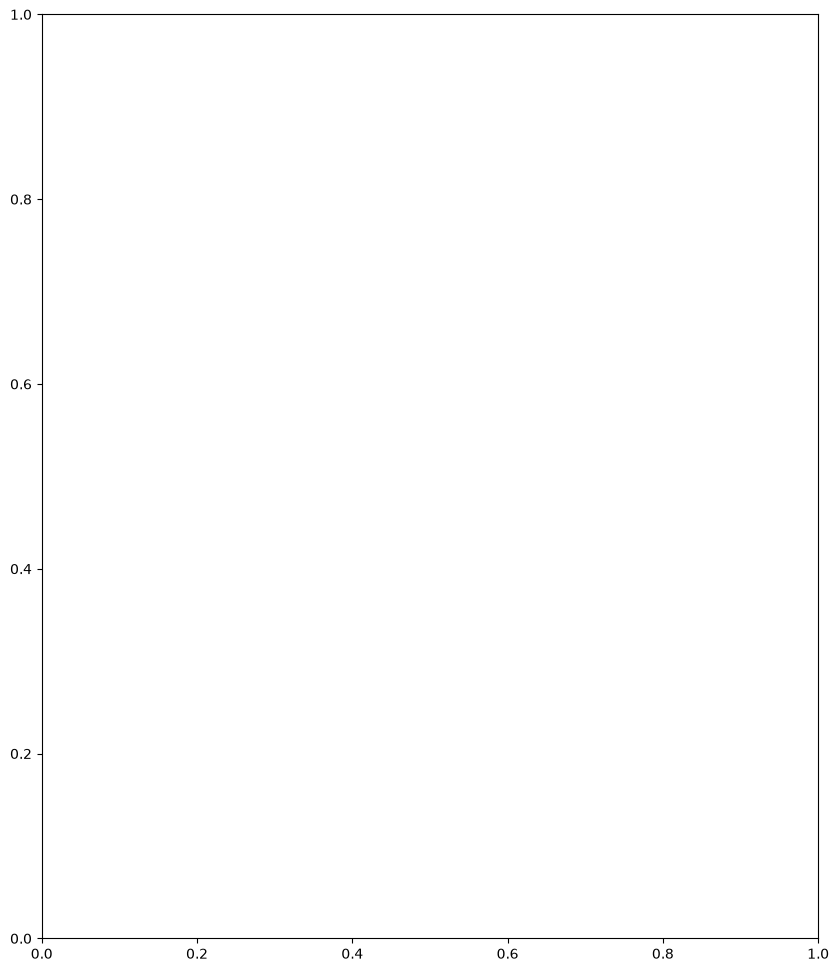

In [ ]:
import matplotlib.pyplot as plt

# plot the isochrones, colored by travel time
fig, ax = plt.subplots(figsize=(12, 12))
isochrones.plot(
    column="travel_time",
    ax=ax,
    legend=True,
    cmap="viridis_r",
    linewidth=2
)
ax.set_title("Transit Isochrones from Downtown Dallas (8:30 AM)")
plt.show()

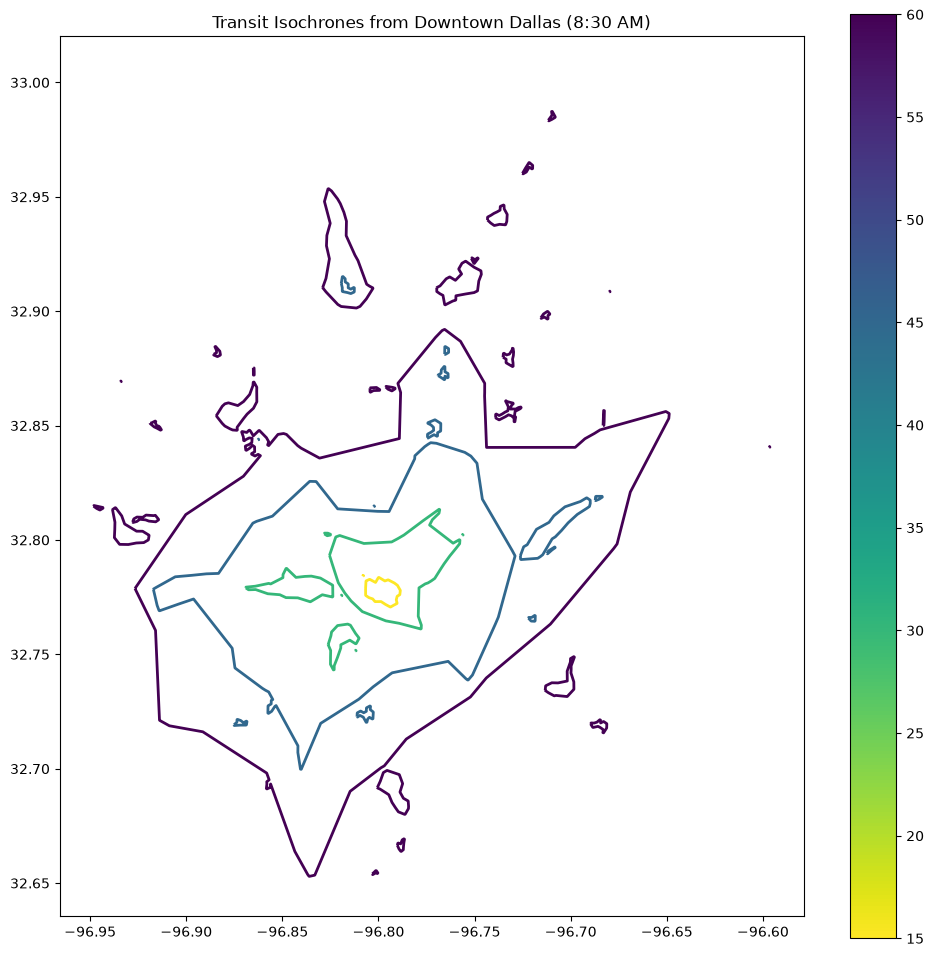

In [ ]:
import matplotlib.pyplot as plt

# convert the travel_time into  minutes so it can be plotted
isochrones["minutes"] = isochrones["travel_time"].dt.total_seconds() / 60

# plot the isochrones, colored by minutes
fig, ax = plt.subplots(figsize=(12, 12))
isochrones.plot(
    column="minutes",
    ax=ax,
    legend=True,
    cmap="viridis_r",
    linewidth=2
)
ax.set_title("Transit Isochrones from Downtown Dallas (8:30 AM)")
plt.show()

In [ ]:
print(f"Total DART tracts: {len(dart)}")
print(f"Tracts WITH income: {dart['median_income'].notna().sum()}")
print(f"Tracts MISSING income: {dart['median_income'].isna().sum()}")

Total DART tracts: 645
Tracts WITH income: 630
Tracts MISSING income: 15


In [ ]:
print(f"Total DART tracts: {len(dart)}")
print(f"Tracts WITH income: {dart['median_income'].notna().sum()}")

Total DART tracts: 1123
Tracts WITH income: 1101


In [ ]:
# match LODES jobs to tract level
lodes = pd.read_csv("lodes/tx_wac_S000_JT00_2023.csv.gz")
lodes["GEOID"] = lodes["w_geocode"].astype(str).str.zfill(15).str[:11]
jobs_by_tract = lodes.groupby("GEOID")["C000"].sum().reset_index()
jobs_by_tract = jobs_by_tract.rename(columns={"C000": "total_jobs"})

# join jobs onto the DART tracts
dart = dart.merge(jobs_by_tract, on="GEOID", how="left")

print(f"DART tracts: {len(dart)}")
print(f"Total jobs across DART region: {dart['total_jobs'].sum():,.0f}")

DART tracts: 1123
Total jobs across DART region: 2,905,949


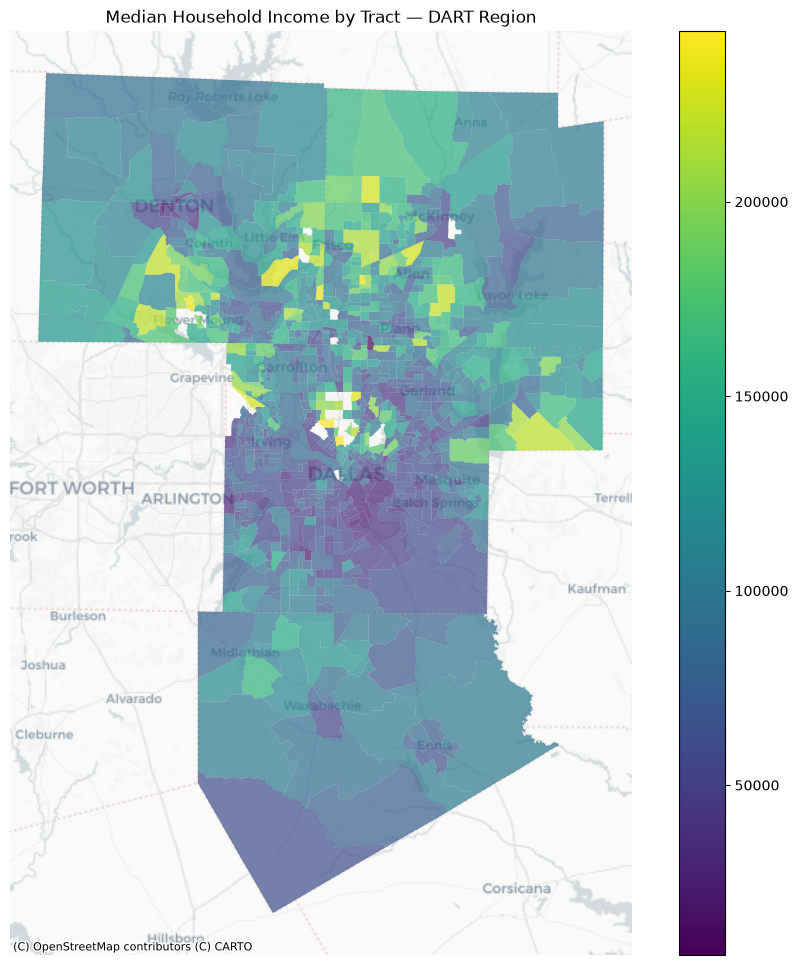

In [10]:
import contextily as cx
import matplotlib.pyplot as plt

# Convert to Web Mercator (the CRS that basemap tiles use)
dart_web = dart.to_crs(epsg=3857)

# Plot income with a basemap underneath
fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(
    column="median_income",
    ax=ax,
    legend=True,
    alpha=0.7,          # slight transparency so the basemap shows through
    cmap="viridis"
)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)
ax.set_title("Median Household Income by Tract — DART Region")
ax.set_axis_off()       # hide the coordinate numbers, looks cleaner
plt.show()

KeyError: 'total_jobs'

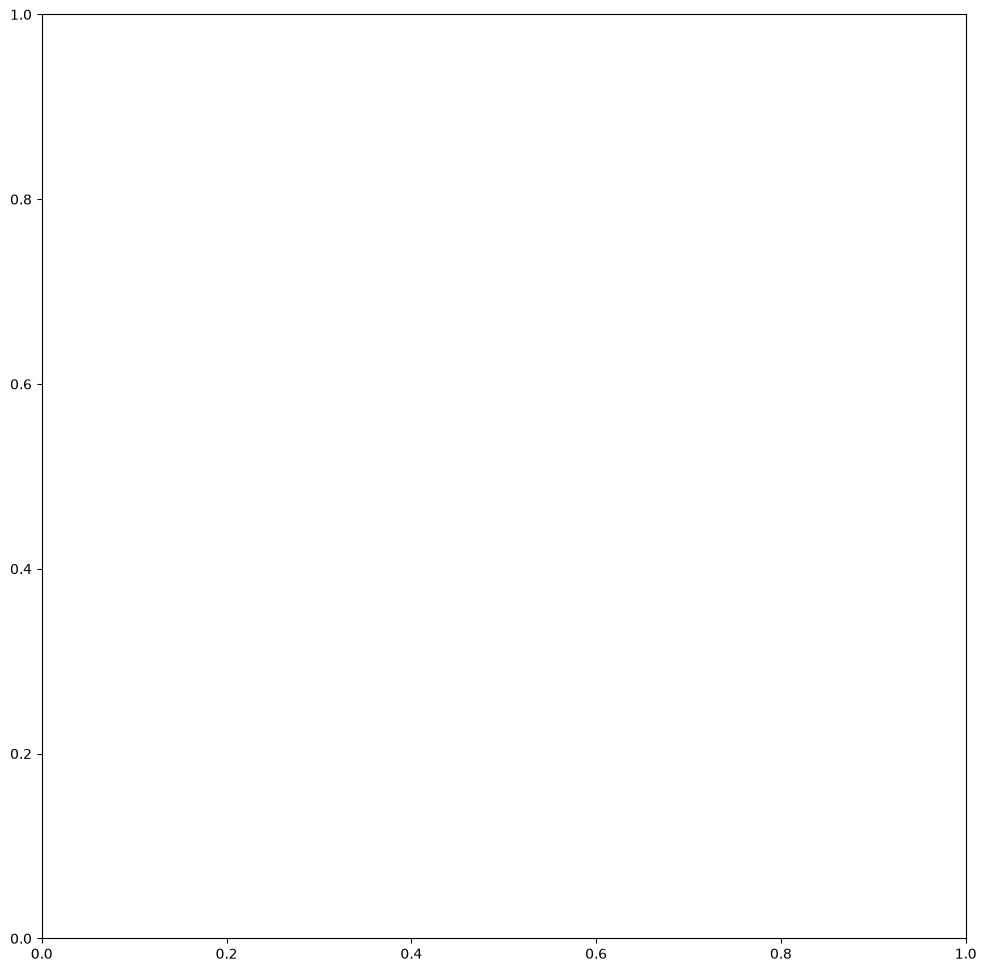

In [11]:
fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(
    column="total_jobs",
    ax=ax,
    legend=True,
    alpha=0.7,
    cmap="plasma"
)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)
ax.set_title("Total Jobs by Tract — DART Region")
ax.set_axis_off()
plt.show()

In [12]:
import pandas as pd

# Roll up LODES jobs to tract level and join onto dart
lodes = pd.read_csv("lodes/tx_wac_S000_JT00_2023.csv.gz")
lodes["GEOID"] = lodes["w_geocode"].astype(str).str.zfill(15).str[:11]
jobs_by_tract = lodes.groupby("GEOID")["C000"].sum().reset_index()
jobs_by_tract = jobs_by_tract.rename(columns={"C000": "total_jobs"})

dart = dart.merge(jobs_by_tract, on="GEOID", how="left")
print(f"Total jobs across DART region: {dart['total_jobs'].sum():,.0f}")

Total jobs across DART region: 2,905,949


In [13]:
dart_web = dart.to_crs(epsg=3857)

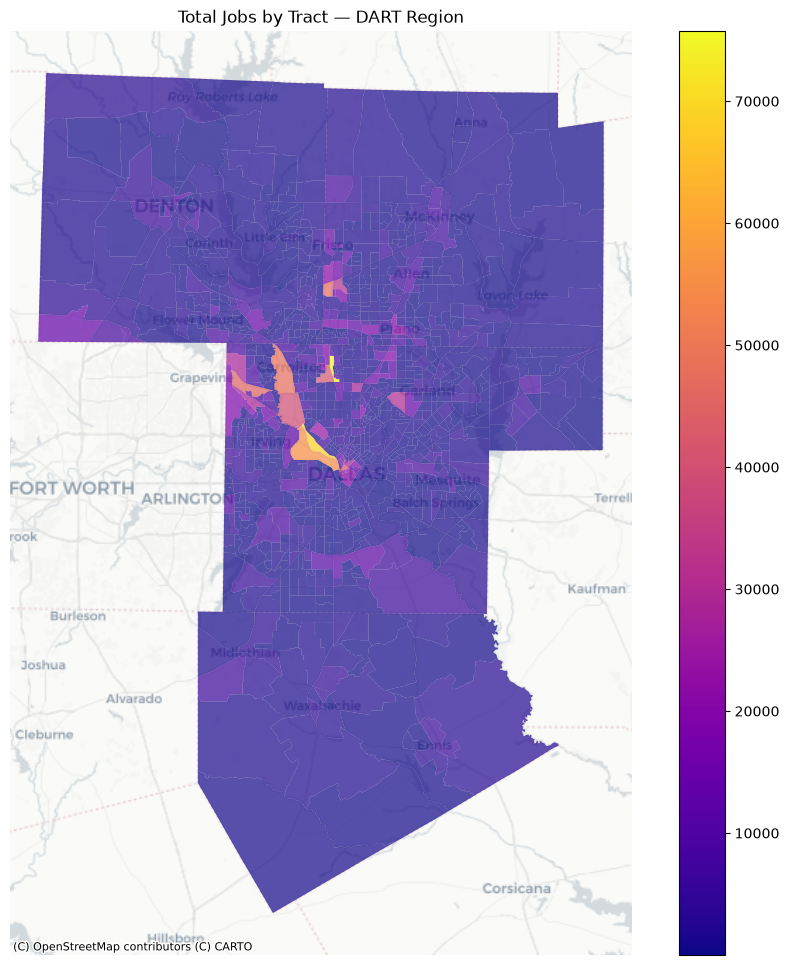

In [14]:
fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(
    column="total_jobs",
    ax=ax,
    legend=True,
    alpha=0.7,
    cmap="plasma"
)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)
ax.set_title("Total Jobs by Tract — DART Region")
ax.set_axis_off()
plt.show()

In [15]:
print(f"Tracts in dart: {len(dart)}")
print(f"Tracts with jobs data: {dart['total_jobs'].notna().sum()}")
print(f"Counties present: {sorted(dart['COUNTYFP'].unique())}")

Tracts in dart: 1123
Tracts with jobs data: 1123
Counties present: ['085', '113', '121', '139', '397']


In [16]:

dart_projected = dart.to_crs("epsg:3083")

dart_projected["centroid"] = dart_projected.geometry.centroid

print(dart_projected["centroid"].iloc[0])

POINT (1814749.613272212 7637688.120612574)


In [17]:
import geopandas as gpd

centroids = dart_projected[["GEOID"]].copy()
centroids = gpd.GeoDataFrame(
    centroids,
    geometry=dart_projected["centroid"],
    crs="epsg:3083"
).to_crs("epsg:4326")   # back to lat/lon for r5py

print(f"Number of centroids: {len(centroids)}")
print(centroids.head(3))

Number of centroids: 1123
         GEOID                    geometry
0  48113017819  POINT (-96.63241 32.81649)
1  48113005400  POINT (-96.81744 32.72731)
2  48113005500  POINT (-96.79954 32.72518)


In [20]:
import datetime
import geopandas as gpd
from r5py import Isochrones, TransportMode

sample = centroids.head(5)

results = []
for idx, row in sample.iterrows():
    origin = gpd.GeoDataFrame(
        {"id": [row["GEOID"]]},
        geometry=[row.geometry],
        crs="EPSG:4326"
    )
    iso = Isochrones(
        network,
        origins=origin,
        departure=datetime.datetime(2026, 6, 12, 8, 30),
        isochrones=[datetime.timedelta(minutes=45)],  # just 45-min for the test
        transport_modes=[TransportMode.TRANSIT, TransportMode.WALK],
    )
    iso["GEOID"] = row["GEOID"]
    results.append(iso)
    print(f"Done tract {row['GEOID']}")

print("Test complete!")

Done tract 48113017819
Done tract 48113005400
Done tract 48113005500
Done tract 48113005300
Done tract 48113005600
Test complete!


In [19]:
from r5py import TransportNetwork, Isochrones, TransportMode

print("Building transport network (this can take a few minutes)...")
network = TransportNetwork(
    "osm/dfw.osm.pbf",
    ["gtfs/google_transit.zip"],
    allow_errors=True
)
print("Network built!")

Building transport network (this can take a few minutes)...
Network built!


/Users/sanjulajuttada/Downloads/transit_research/.venv/lib/python3.14/site-packages/r5py/r5/transport_network.py:266: RuntimeWarning: R5 reported the following issues with GTFS file google_transit.zip: 
RangeError: fare_attributes line 26: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 7: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 19: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 11: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 15: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 23: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 4: Number 2678400.0 outside of acceptable range [0.0,86400.0].
  warnings.warn(


In [21]:
import time

start = time.time()
test_origin = gpd.GeoDataFrame(
    {"id": [centroids.iloc[0]["GEOID"]]},
    geometry=[centroids.iloc[0].geometry],
    crs="EPSG:4326"
)
iso = Isochrones(
    network,
    origins=test_origin,
    departure=datetime.datetime(2026, 6, 12, 8, 30),
    isochrones=[datetime.timedelta(minutes=45)],
    transport_modes=[TransportMode.TRANSIT, TransportMode.WALK],
)
elapsed = time.time() - start
print(f"One tract took {elapsed:.1f} seconds")
print(f"Estimated time for all 1,123 tracts: {elapsed * 1123 / 60:.0f} minutes")

One tract took 28.4 seconds
Estimated time for all 1,123 tracts: 531 minutes


In [22]:
import pandas as pd
import geopandas as gpd

sample_isochrones = pd.concat(results, ignore_index=True)
sample_isochrones = gpd.GeoDataFrame(sample_isochrones, crs="EPSG:4326")

print(f"Number of sample isochrones: {len(sample_isochrones)}")
print(sample_isochrones[["GEOID", "travel_time"]])

Number of sample isochrones: 5
         GEOID     travel_time
0  48113017819 0 days 00:45:00
1  48113005400 0 days 00:45:00
2  48113005500 0 days 00:45:00
3  48113005300 0 days 00:45:00
4  48113005600 0 days 00:45:00


In [23]:
job_points = centroids.merge(
    dart[["GEOID", "total_jobs"]],
    on="GEOID",
    how="left"
)
print(f"Job points: {len(job_points)}")
print(job_points.head(3))
print(f"Total jobs across all points: {job_points['total_jobs'].sum():,.0f}")

Job points: 1123
         GEOID                    geometry  total_jobs
0  48113017819  POINT (-96.63241 32.81649)        2010
1  48113005400  POINT (-96.81744 32.72731)         556
2  48113005500  POINT (-96.79954 32.72518)         193
Total jobs across all points: 2,905,949


In [24]:
#for each isochrone, find which job points fall inside it, then sum their jobs
reachable = gpd.sjoin(
    job_points,
    sample_isochrones,
    how="inner",
    predicate="within"
)

#sum the jobs reachable from each origin tract (grouped by the isochrone's GEOID)
jobs_reachable = reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
jobs_reachable = jobs_reachable.rename(columns={
    "GEOID_right": "origin_tract",
    "total_jobs": "jobs_reachable_45min"
})

print(jobs_reachable)

Empty DataFrame
Columns: [origin_tract, jobs_reachable_45min]
Index: []


In [25]:
print("Job points CRS:", job_points.crs)
print("Isochrones CRS:", sample_isochrones.crs)

Job points CRS: epsg:4326
Isochrones CRS: EPSG:4326


In [26]:
print(sample_isochrones.geometry.geom_type)

0    MultiLineString
1    MultiLineString
2    MultiLineString
3    MultiLineString
4    MultiLineString
dtype: str


In [ ]:
from shapely.ops import polygonize, unary_union
import geopandas as gpd

#filled polygon
filled = []
for idx, row in sample_isochrones.iterrows():
    # polygonize turns the closed rings into polygon(s); union merges them into one shape
    polys = list(polygonize(row.geometry))
    if polys:
        filled_geom = unary_union(polys)
    else:
        filled_geom = None
    filled.append(filled_geom)

sample_isochrones_filled = sample_isochrones.copy()
sample_isochrones_filled["geometry"] = filled
sample_isochrones_filled = sample_isochrones_filled[sample_isochrones_filled.geometry.notna()]

print(sample_isochrones_filled.geometry.geom_type)

0         Polygon
1    MultiPolygon
2    MultiPolygon
3    MultiPolygon
4    MultiPolygon
dtype: str


In [28]:
# Count jobs inside each filled isochrone
reachable = gpd.sjoin(
    job_points,
    sample_isochrones_filled,
    how="inner",
    predicate="within"
)

jobs_reachable = reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
jobs_reachable = jobs_reachable.rename(columns={
    "GEOID_right": "origin_tract",
    "total_jobs": "jobs_reachable_45min"
})

print(jobs_reachable)

  origin_tract  jobs_reachable_45min
0  48113005300                 74245
1  48113005400                117006
2  48113005500                 29917
3  48113005600                 65850
4  48113017819                 13674
